<a href="https://colab.research.google.com/github/drchoi1/LING609_demo/blob/main/LING609_%60brms%60_logistic_regression_example.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LING609 Fall 2026: Logistic regression example

This Google Colab notebook accompanies in-class lecture on 10/22. It implements the logistic analysis from Nicenboim et al's Chapter 4.


In [1]:
### This code chunk sets us up to run. It'll take about 20 minutes.
### Please go to "Runtime > Restart session" before running this chunk.
### install brms / cmdstanr / tidyverse
options(repos = c(CRAN = "https://packagemanager.posit.co/cran/__linux__/jammy/latest"))
install.packages(c("brms", "emmeans", "dplyr", "ggplot2", "cmdstanr", "tidyverse", "bayesplot"),
                 repos = c("https://stan-dev.r-universe.dev",
                           getOption("repos")))
### load cmdstanr and set number of cores
library(cmdstanr)
install_cmdstan(cores = 2)

### load libraries that will be used in exercises
install.packages("remotes")
remotes::install_github("bnicenboim/bcogsci")
library(brms)
library(bcogsci)
library(emmeans)
library(bayesplot)
library(dplyr)
library(ggplot2)
options(brms.backend = "cmdstanr", mc.cores = 2)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘StanHeaders’, ‘inline’, ‘gridExtra’, ‘RcppParallel’, ‘QuickJSR’, ‘RcppEigen’, ‘BH’, ‘tensorA’, ‘distributional’, ‘Brobdingnag’, ‘globals’, ‘listenv’, ‘parallelly’, ‘quadprog’, ‘plyr’, ‘rstan’, ‘loo’, ‘posterior’, ‘rstantools’, ‘bridgesampling’, ‘future’, ‘future.apply’, ‘matrixStats’, ‘nleqslv’, ‘coda’, ‘abind’, ‘estimability’, ‘mvtnorm’, ‘numDeriv’, ‘checkmate’, ‘ggdist’, ‘ggridges’, ‘reshape2’


This is cmdstanr version 0.9.0

- CmdStanR documentation and vignettes: mc-stan.org/cmdstanr

- Use set_cmdstan_path() to set the path to CmdStan

- Use install_cmdstan() to install CmdStan

The C++ toolchain required for CmdStan is setup properly!

* Latest CmdStan release is v2.40.0

* Installing CmdStan v2.40.0 in /root/.cmdstan/cmdstan-2.40.0

* Downloading cmdstan-2.40.0.tar.gz from GitHub...

* Download complete

* Unpacking archive...

* Building CmdStan binaries...



g++ -Wno-deprecated-declarations -std=c++17 -pthread -D_REENTRANT -Wno-sign-compare -Wno-ignored-attributes -Wno-class-memaccess      -isystem stan/lib/stan_math/lib/tbb_2020.3/include    -O3 -I src -I stan/src -I stan/lib/rapidjson_1.1.0/ -I lib/CLI11-1.9.1/ -I stan/lib/stan_math/ -isystem stan/lib/stan_math/lib/eigen_5.0.1 -isystem stan/lib/stan_math/lib/boost_1.87.0 -isystem stan/lib/stan_math/lib/sundials_6.1.1/include -isystem stan/lib/stan_math/lib/sundials_6.1.1/src/sundials    -DBOOST_DISABLE_ASSERTS          -c -MT src/cmdstan/main.o -MM -E -MG -MP -MF src/cmdstan/main.d src/cmdstan/main.cpp
g++ -Wno-deprecated-declarations -std=c++17 -pthread -D_REENTRANT -Wno-sign-compare -Wno-ignored-attributes -Wno-class-memaccess      -isystem stan/lib/stan_math/lib/tbb_2020.3/include    -O3 -I src -I stan/src -I stan/lib/rapidjson_1.1.0/ -I lib/CLI11-1.9.1/ -I stan/lib/stan_math/ -isystem stan/lib/stan_math/lib/eigen_5.0.1 -isystem stan/lib/stan_math/lib/boost_1.87.0 -isystem stan/lib/st

* Finished installing CmdStan to /root/.cmdstan/cmdstan-2.40.0


CmdStan path set to: /root/.cmdstan/cmdstan-2.40.0

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)




rbibutils (NA -> 2.4.1  ) [CRAN]
rootSolve (NA -> 1.8.2.4) [CRAN]
Rdpack    (NA -> 2.6.6  ) [CRAN]


Installing 3 packages: rbibutils, rootSolve, Rdpack

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



── R CMD build ─────────────────────────────────────────────────────────────────
* checking for file ‘/tmp/Rtmp31kPnx/remotesa9c77dcc786/bnicenboim-bcogsci-d90fc01/DESCRIPTION’ ... OK
* preparing ‘bcogsci’:
* checking DESCRIPTION meta-information ... OK
* installing the package (it is needed to process help pages)
* saving partial Rd database
* checking for LF line-endings in source and make files and shell scripts
* checking for empty or unneeded directories
  NB: this package now depends on R (>= 3.5.0)
  serialize/load version 3 cannot be read in older versions of R.
  File(s) containing such objects:
    ‘bcogsci/data/df_buerki.rda’ ‘bcogsci/data/df_chineseRCs.rda’
    ‘bcogsci/data/df_dillonE1.rda’ ‘bcogsci/data/df_dillonrep.rda’
    ‘bcogsci/data/df_discreteagrmt.rda’ ‘bcogsci/data/df_dutch.rda’
    ‘bcogsci/data/df_english.rda’ ‘bcogsci/data/df_gibsonwu.rda’
    ‘bcogsci/data/df_gibsonwu2.rda’ ‘bcogsci/data/df_lagoE1.rda’
    ‘bcogsci/data/df_persianE1.rda’ ‘bcogsci/data/df_pola

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Loading required package: Rcpp

Loading 'brms' package (version 2.23.0). Useful instructions
can be found by typing help('brms'). A more detailed introduction
to the package is available through vignette('brms_overview').


Attaching package: ‘brms’


The following object is masked from ‘package:stats’:

    ar


Welcome to emmeans.
Caution: You lose important information if you filter this package's results.
See '? untidy'

This is bayesplot version 1.16.0.9000

- Online documentation and vignettes at mc-stan.org/bayesplot

- bayesplot theme set to bayesplot::theme_default()

   * Does _not_ affect other ggplot2 plots

   * See ?bayesplot_theme_set for details on theme setting


Attaching package: ‘bayesplot’


The following object is masked from ‘package:brms’:

    rhat



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are m

In [4]:
### Basic fitting code chunk
data("df_recall")
head(df_recall)

## Center my predictor
df_recall$c_set_size <- df_recall$set_size-5

## Summarize accuracy:
df_summary <- df_recall %>% group_by(c_set_size) %>% summarize(mean.acc = mean(correct), n = n())
print(df_summary)

## Basic logistic regression:
fit_recall <- brm(correct ~ 1 + c_set_size, # correct: DV (response variable), 1: intercept, c_set_size: predictor
                  data = df_recall,
                  family = bernoulli(link = logit),
                  prior = c(prior(normal(0, 1.5), class = Intercept),
                            prior(normal(0, 0.1), class = b, coef = c_set_size))
                  )

summary(fit_recall)


subj,set_size,correct,trial,session,block,tested
<chr>,<int>,<int>,<int>,<int>,<int>,<int>
10,4,1,1,1,1,2
10,8,0,4,1,1,8
10,2,1,9,1,1,2
10,6,1,23,1,1,2
10,4,1,5,1,2,3
10,8,0,7,1,2,5


# A tibble: 4 × 3
  c_set_size mean.acc     n
       <dbl>    <dbl> <int>
1         -3    1        23
2         -1    0.957    23
3          1    0.913    23
4          3    0.609    23


Start sampling



Running MCMC with 4 chains, at most 2 in parallel...

Chain 1 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 1 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 1 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 1 Iteration:  300 / 2000 [ 15%]  (Warmup) 
Chain 1 Iteration:  400 / 2000 [ 20%]  (Warmup) 
Chain 1 Iteration:  500 / 2000 [ 25%]  (Warmup) 
Chain 1 Iteration:  600 / 2000 [ 30%]  (Warmup) 
Chain 1 Iteration:  700 / 2000 [ 35%]  (Warmup) 
Chain 1 Iteration:  800 / 2000 [ 40%]  (Warmup) 
Chain 1 Iteration:  900 / 2000 [ 45%]  (Warmup) 
Chain 1 Iteration: 1000 / 2000 [ 50%]  (Warmup) 
Chain 1 Iteration: 1001 / 2000 [ 50%]  (Sampling) 
Chain 1 Iteration: 1100 / 2000 [ 55%]  (Sampling) 
Chain 1 Iteration: 1200 / 2000 [ 60%]  (Sampling) 
Chain 1 Iteration: 1300 / 2000 [ 65%]  (Sampling) 
Chain 1 Iteration: 1400 / 2000 [ 70%]  (Sampling) 
Chain 1 Iteration: 1500 / 2000 [ 75%]  (Sampling) 
Chain 1 Iteration: 1600 / 2000 [ 80%]  (Sampling) 
Chain 1 Iteration: 1700 / 2000 [ 85%]  (Sampling) 

Loading required namespace: rstan



 Family: bernoulli 
  Links: mu = logit 
Formula: correct ~ 1 + c_set_size 
   Data: df_recall (Number of observations: 92) 
  Draws: 4 chains, each with iter = 2000; warmup = 1000; thin = 1;
         total post-warmup draws = 4000

Regression Coefficients:
           Estimate Est.Error l-95% CI u-95% CI Rhat Bulk_ESS Tail_ESS
Intercept      1.91      0.30     1.34     2.53 1.00     3124     2912
c_set_size    -0.18      0.08    -0.35    -0.03 1.00     2564     2533

Draws were sampled using sample(hmc). For each parameter, Bulk_ESS
and Tail_ESS are effective sample size measures, and Rhat is the potential
scale reduction factor on split chains (at convergence, Rhat = 1).

[1] 2.24126

[1] 9.405175

[1] 0.903894

mean      2.5%     97.5% 
0.8671125 0.7931408 0.9263498

mean      2.5%     97.5% 
0.8354082 0.7077748 0.9715609

[1] 0.99225

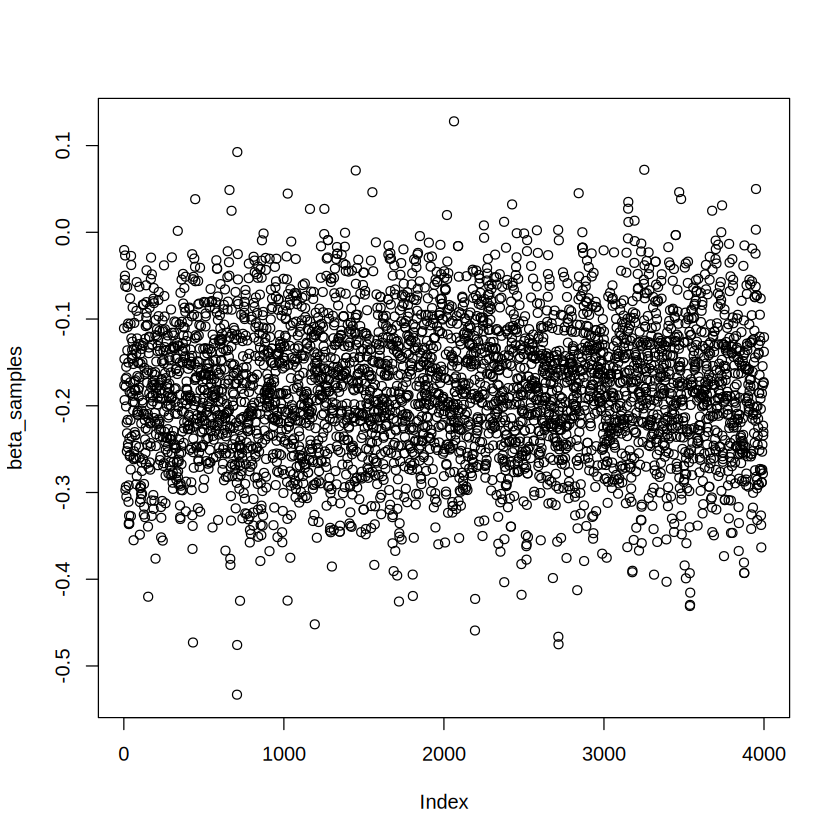

In [12]:
### Summarizing and inspecting the model code chunk

## Summarize the whole model

## Plot the whole model

#===== skipped =====#

## Summarize the posterior over key variables only
## Extract the posterior samples themselves from the model themselves
intercept_samples <- as_draws_df(fit_recall)$b_Intercept
# head(intercept_samples)
# plot(intercept_samples)

## Recall that the intercept is the log-odds of a correct answer at the mean set size value. We can convert to different scales:
intercept_samples[1]

## First, convert log-odds to odds:
exp(intercept_samples[1])

## Next, convert log-odds to probabilities:
plogis(intercept_samples[1])

### ALWAYS TRANSFORM (`plogis` = reverse logit) AND SUMMARIZE

## Let's convert to probabilities/accuracies and then take the average.
av_accuracy <- plogis(intercept_samples)
c(mean = mean(av_accuracy), quantile(av_accuracy, c(0.025,0.975)))

## How well does this align with the empirical data?

## Reporting odds for beta
beta_samples <- as_draws_df(fit_recall)$b_c_set_size
plot(beta_samples)

beta_in_odds <- exp(beta_samples)
c(mean = mean(beta_in_odds), quantile(beta_in_odds, c(0.025,0.975)))

## Statistical hypothesis: B < 0. We can directly inspect the samples to calculate this:
mean(beta_samples < 0)  # Pr(beta_hat < 0) = .992


Note: in most cases the default test statistic 'mean' is too weak to detect anything of interest.
`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


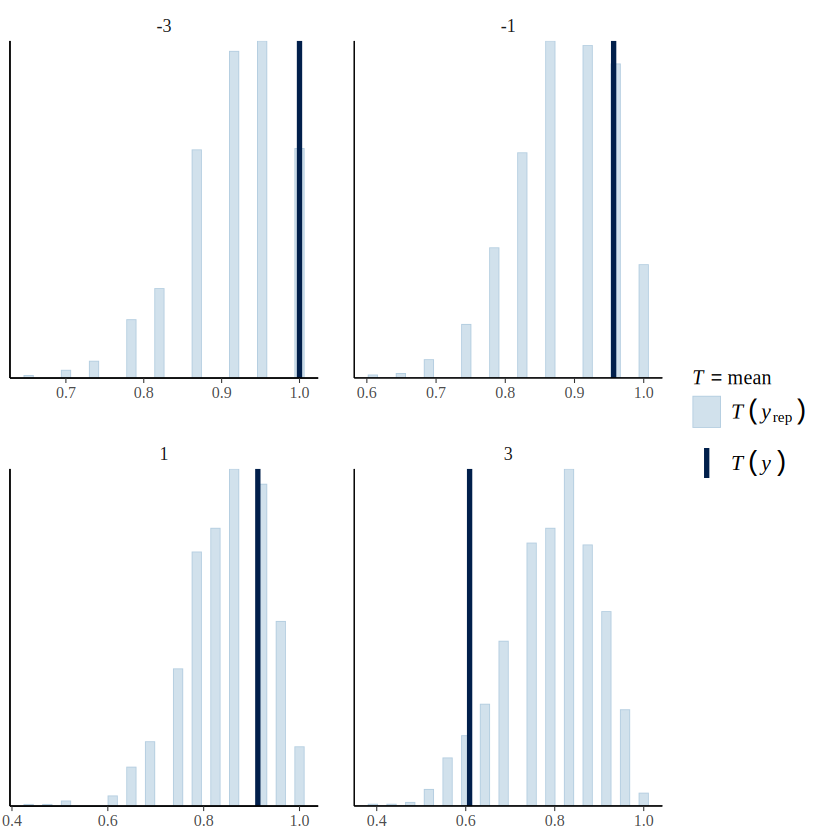

In [13]:
## Let's look at accuracy rate by condition for our posterior predictive check
## Do we feel this is acceptable?
pp_check(fit_recall, type = "stat_grouped", stat = "mean", group = "c_set_size", ndraws = 1000)



Start sampling



Running MCMC with 4 chains, at most 2 in parallel...

Chain 1 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 1 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 1 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 1 Iteration:  300 / 2000 [ 15%]  (Warmup) 
Chain 1 Iteration:  400 / 2000 [ 20%]  (Warmup) 
Chain 1 Iteration:  500 / 2000 [ 25%]  (Warmup) 
Chain 1 Iteration:  600 / 2000 [ 30%]  (Warmup) 
Chain 1 Iteration:  700 / 2000 [ 35%]  (Warmup) 
Chain 1 Iteration:  800 / 2000 [ 40%]  (Warmup) 
Chain 1 Iteration:  900 / 2000 [ 45%]  (Warmup) 
Chain 1 Iteration: 1000 / 2000 [ 50%]  (Warmup) 
Chain 1 Iteration: 1001 / 2000 [ 50%]  (Sampling) 
Chain 1 Iteration: 1100 / 2000 [ 55%]  (Sampling) 
Chain 1 Iteration: 1200 / 2000 [ 60%]  (Sampling) 
Chain 1 Iteration: 1300 / 2000 [ 65%]  (Sampling) 
Chain 1 Iteration: 1400 / 2000 [ 70%]  (Sampling) 
Chain 1 Iteration: 1500 / 2000 [ 75%]  (Sampling) 
Chain 1 Iteration: 1600 / 2000 [ 80%]  (Sampling) 
Chain 1 Iteration: 1700 / 2000 [ 85%]  (Sampling) 

Note: in most cases the default test statistic 'mean' is too weak to detect anything of interest.
`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


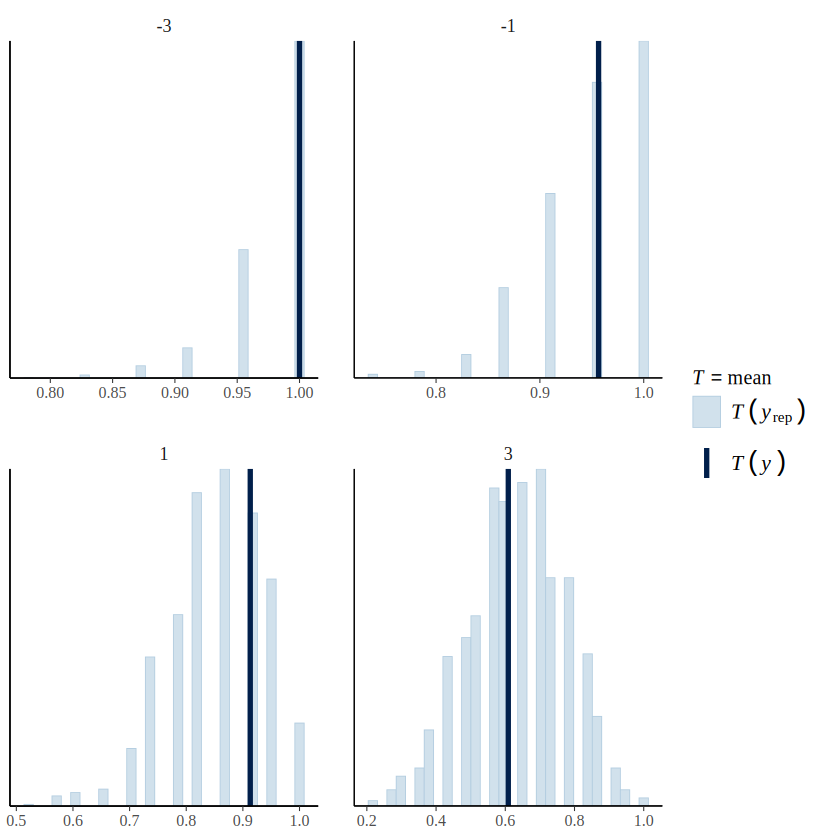

In [14]:
fit_recall_5 <- brm(correct ~ 1 + c_set_size, # correct: DV (response variable), 1: intercept, c_set_size: predictor
                  data = df_recall,
                  family = bernoulli(link = logit),
                  prior = c(prior(normal(0, 1.5), class = Intercept),
                            prior(normal(0, 0.5), class = b, coef = c_set_size))
                  )
pp_check(fit_recall_5, type = "stat_grouped", stat = "mean", group = "c_set_size", ndraws = 1000)

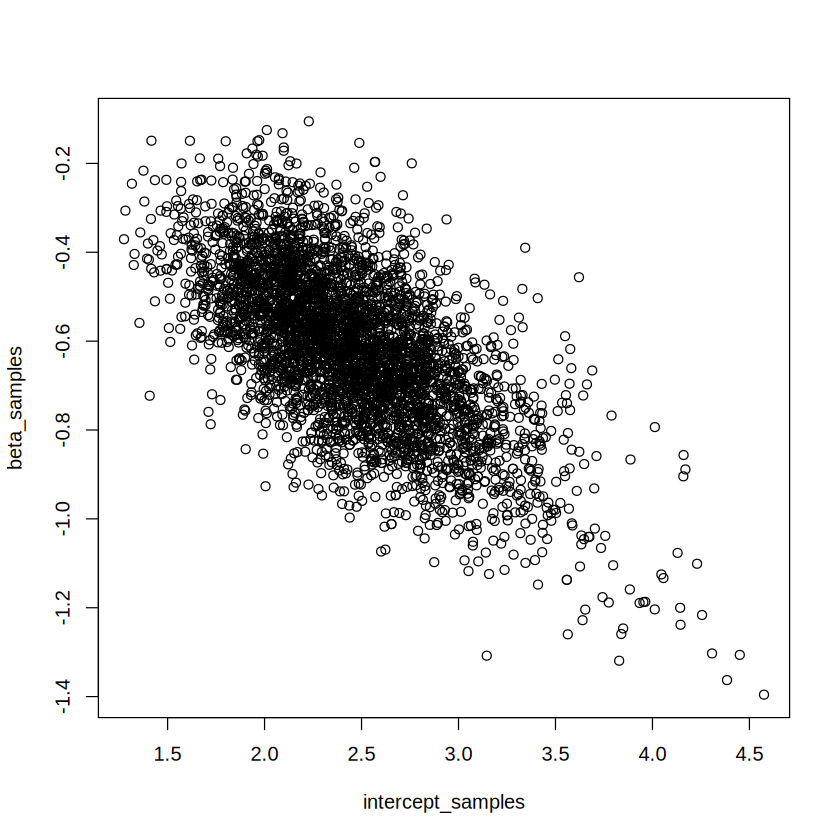

In [15]:
beta_samples <- as_draws_df(fit_recall_5)$b_c_set_size
intercept_samples <- as_draws_df(fit_recall_5)$b_Intercept

plot(intercept_samples, beta_samples)

# each datapoint in this plot can make predictions about the fitted model

In [18]:
### Introduction to emmmeans (estimated marginal means)
# install.packages("emm")
# library(emm)
library(emmeans)
emm <- emmeans(fit_recall_5, ~ c_set_size, epred = TRUE, at = list(c_set_size = c(-3, -1, 1, 3)))
emm_summary <- as.data.frame(summary(emm, point.est = mean))

### Compare model estimated means, to observed means
emm_summary
df_summary

,c_set_size,emmean,lower.HPD,upper.HPD
,<dbl>,<dbl>,<dbl>,<dbl>
1,-3,0.9813000,0.9508586,0.9996312
2,-1,0.9491431,0.8983345,0.9914494
3,1,0.8567297,0.7738222,0.9330331
4,3,0.6404527,0.4618900,0.8189117


c_set_size,mean.acc,n
<dbl>,<dbl>,<int>
-3,1.0000000,23
-1,0.9565217,23
1,0.9130435,23
3,0.6086957,23


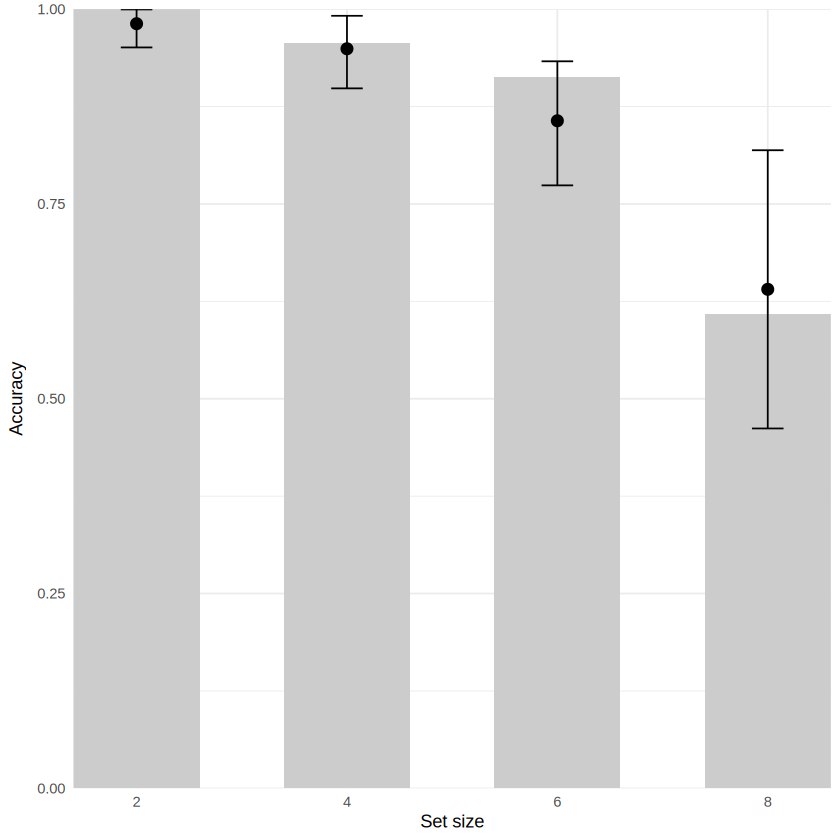

In [19]:
#### Code for plotting
### First, combine predicted and observed means into a single dataframe
### then add a new 'cond' column that is a 'string' we can use for plotting.
plot_df <- left_join(df_summary, emm_summary, by = c("c_set_size")) %>%
  mutate(cond = as.character(c_set_size+5))

#### Plot empirical and model-fitted estimates
ggplot(plot_df, aes(x = cond)) +
  geom_col(aes(y = mean.acc), fill = "grey80", width = 0.6) +              ### Create columns; this references the 'mean.acc' variable
  geom_errorbar(aes(ymin = lower.HPD, ymax = upper.HPD), width = 0.15) +  ### Create error bars; this references the 'lower.HPD' and 'upper.HPD' variables
  geom_point(aes(y = emmean), size = 3) +                                  ### Create point; this references the 'emmean' variable
  coord_cartesian(ylim = c(0, 1), expand = FALSE) +                        ### Set y-limits to 0,1; standard for accuracy.
  labs(x = "Set size", y = "Accuracy") +
  theme_minimal()

### Suggested caption: "Bars represented empirical accuracy per condition. Points and error bars represent model estimate with 95% HPD interval."
